# 01 - Data quality notebook: UCI AI4I 2020 (Week 1, Day 2)

**Purpose:** inspect columns, units, class balance, missing values, duplicates and label definitions; decide which columns are features and which are targets.

**Source:** S. Matzka, *AI4I 2020 Predictive Maintenance Dataset*, UCI Machine Learning Repository, DOI 10.24432/C5HS5C (CC BY 4.0).
**The data is synthetic.** Nothing here shows performance on real factory telemetry.

In [1]:
import sys, warnings, hashlib
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent / "ml" / "src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pm_ml import config as C
from pm_ml.data import load_raw, load_clean, validate, sha256
from pm_ml.features import add_engineered
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
print("file:", C.RAW_CSV.name, "| sha256:", sha256())

file: ai4i2020.csv | sha256: 59db4f1d9c34c58136d89e5a006ec190dcea19e9dbea74f6b3b0c6f22a44d183


## 1. Structure, types, missing values, duplicates

In [2]:
raw = load_raw()
print(raw.shape)
display(raw.head(3))
print(raw.dtypes.to_string())
print("\nmissing values:", int(raw.isna().sum().sum()))
df = load_clean()
print("duplicate rows (ignoring UDI):", int(df.drop(columns=["udi"]).duplicated().sum()))
print("UDI unique:", df.udi.is_unique, "| Product ID unique:", df.product_id.is_unique)
print("distinct Product IDs vs rows:", df.product_id.nunique(), "/", len(df))

(10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0


UDI                          int64
Product ID                     str
Type                           str
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64

missing values: 0
duplicate rows (ignoring UDI): 0
UDI unique: True | Product ID unique: True
distinct Product IDs vs rows: 10000 / 10000


`Product ID` is a product-variant serial number (L/M/H + number), **not a machine identifier**, and the file has no timestamp. The platform therefore needs a simulator / replay to assign `machine_id` and `timestamp` (documented assumption).

In [3]:
checks = validate(df)
pd.DataFrame({k: {"ok": ok, "observed": detail} for k, (ok, detail) in checks.items()}).T

,ok,observed
row_count,True,10000
no_missing,True,0
no_duplicate_rows,True,0
udi_unique,True,None
types_valid,True,"[H, L, M]"
count_machine_failure,True,339
count_TWF,True,46
count_HDF,True,115
count_PWF,True,95
count_OSF,True,98


## 2. Units and observed ranges

In [4]:
units = {"air_temperature_k": "K", "process_temperature_k": "K", "rotational_speed_rpm": "rpm", "torque_nm": "Nm", "tool_wear_min": "min"}
desc = df[C.RAW_NUMERIC].describe().T[["min", "mean", "std", "max"]].round(2)
desc.insert(0, "unit", pd.Series(units))
desc["API valid range"] = [C.VALID_RANGES[c] for c in desc.index]
desc

,unit,min,mean,std,max,API valid range
air_temperature_k,K,295.3,300.00,2.00,304.5,"(250.0, 400.0)"
process_temperature_k,K,305.7,310.01,1.48,313.8,"(250.0, 450.0)"
rotational_speed_rpm,rpm,1168.0,1538.78,179.28,2886.0,"(1.0, 10000.0)"
torque_nm,Nm,3.8,39.99,9.97,76.6,"(0.0, 500.0)"
tool_wear_min,min,0.0,107.95,63.65,253.0,"(0.0, 1000.0)"


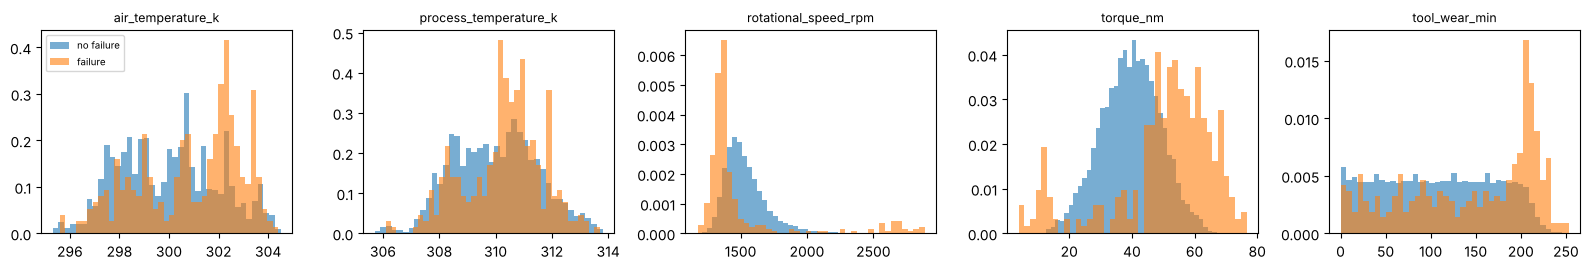

In [5]:
fig, ax = plt.subplots(1, 5, figsize=(16, 2.8))
for a, c in zip(ax, C.RAW_NUMERIC):
    a.hist(df.loc[df.fault_class == "none", c], bins=40, alpha=.6, density=True, label="no failure")
    a.hist(df.loc[df.fault_class != "none", c], bins=40, alpha=.6, density=True, label="failure")
    a.set_title(c, fontsize=9)
ax[0].legend(fontsize=7); fig.tight_layout()
fig.savefig(C.FIG_DIR / "eda_feature_distributions.png", dpi=120); plt.show()

## 3. Labels and class balance

In [6]:
modes = ["machine_failure"] + C.MODE_COLS
tab = pd.DataFrame({"count": df[modes].sum(), "rate_%": (df[modes].mean() * 100).round(2)})
tab

,count,rate_%
machine_failure,339,3.39
TWF,46,0.46
HDF,115,1.15
PWF,95,0.95
OSF,98,0.98
RNF,19,0.19


In [7]:
df["n_modes"] = df[C.MODE_COLS].sum(axis=1)
print(pd.crosstab(df.n_modes, df.machine_failure, rownames=["flagged modes (TWF..RNF)"], colnames=["machine_failure"]))
print("\nfailure=1 but NO mode flagged:", int(((df.machine_failure == 1) & (df.n_modes == 0)).sum()))
print("RNF=1 but machine_failure=0   :", int(((df.RNF == 1) & (df.machine_failure == 0)).sum()))
print("rows with 2+ modes            :", int((df.n_modes >= 2).sum()))

machine_failure              0    1
flagged modes (TWF..RNF)           
0                         9643    9
1                           18  306
2                            0   23
3                            0    1

failure=1 but NO mode flagged: 9
RNF=1 but machine_failure=0   : 18
rows with 2+ modes            : 24


**Label quirks found (observed in this file):**
- 9 rows have `machine_failure = 1` with no failure mode flagged.
- 18 of the 19 `RNF = 1` rows have `machine_failure = 0`, so the RNF flag is inconsistent with the aggregate label.
- 24 failures carry two or more modes at once.
- The UCI text describes 120 tool-wear events (69 replaced, 51 failed) and 5 random failures; the label columns contain **46** `TWF` and **19** `RNF` rows. I use the labels as given and flag the mismatch.

**Fault-class target (decision):** `none`, `TWF`, `HDF`, `PWF`, `OSF`, `other` (= failure with no flagged mode, or 2+ modes). Rows with only the RNF flag stay `none`.

In [8]:
print(df.fault_class.value_counts().to_string())
print("\nfailure rate by product type (%):")
print((df.groupby("product_type").machine_failure.mean() * 100).round(2).to_string())

fault_class
none     9661
HDF       106
PWF        80
OSF        78
TWF        42
other      33

failure rate by product type (%):
product_type
H    2.09
L    3.92
M    2.77


## 4. How the labels were generated (rule check)

The dataset documentation describes deterministic rules for HDF, PWF and OSF. If those rules reproduce the labels exactly, then a model given the derived features can recover them, and scores on AI4I will overstate real-world difficulty.

In [9]:
d = pd.concat([df, add_engineered(df[C.INPUT_COLUMNS])[C.ENGINEERED]], axis=1)
rules = {
 "HDF": (d.temp_diff_k < 8.6) & (d.rotational_speed_rpm < 1380),
 "PWF": (d.power_w < 3500) | (d.power_w > 9000),
 "OSF": d.strain_minnm > d.product_type.map({"L": 11000, "M": 12000, "H": 13000}),
}
rows = []
for m, r in rules.items():
    rows.append({"mode": m, "rule_true": int(r.sum()), "label_true": int(d[m].sum()),
                 "rule_true_label_false": int((r & (d[m] == 0)).sum()), "rule_false_label_true": int((~r & (d[m] == 1)).sum())})
pd.DataFrame(rows).set_index("mode")

,rule_true,label_true,rule_true_label_false,rule_false_label_true
mode,,,,
HDF,115,115,0,0
PWF,95,95,0,0
OSF,98,98,0,0


**HDF, PWF and OSF labels are exact functions of the inputs** (zero disagreements). TWF is different: it is tied to a random wear threshold between 200 and 240 min, so it cannot be determined from the inputs.

In [10]:
bins = [0, 150, 180, 200, 210, 220, 230, 260]
d["wear_bin"] = pd.cut(d.tool_wear_min, bins, right=False)
t = d.groupby("wear_bin").agg(rows=("TWF", "size"), TWF=("TWF", "sum"))
t["TWF_rate_%"] = (t.TWF / t.rows * 100).round(1)
t

,rows,TWF,TWF_rate_%
wear_bin,,,
"[0, 150)",6910,0,0.0
"[150, 180)",1370,0,0.0
"[180, 200)",919,1,0.1
"[200, 210)",407,17,4.2
"[210, 220)",253,12,4.7
"[220, 230)",96,9,9.4
"[230, 260)",45,7,15.6


Even in the highest wear bins, most rows do **not** fail from tool wear. A classifier that picks the most likely class will rarely pick TWF; at best it can report an elevated risk.

## 5. Which columns exist at prediction time?

In [11]:
avail = pd.DataFrame([
 ("product_type (Type)", "feature", "yes"),
 ("air_temperature_k", "feature", "yes"), ("process_temperature_k", "feature", "yes"),
 ("rotational_speed_rpm", "feature", "yes"), ("torque_nm", "feature", "yes"), ("tool_wear_min", "feature", "yes"),
 ("temp_diff_k, power_w, strain_minnm", "derived from the 5 inputs", "yes (computed)"),
 ("UDI, Product ID", "identifier", "no - excluded"),
 ("machine_failure, TWF, HDF, PWF, OSF, RNF", "target / label", "no - never a feature"),
], columns=["column", "role", "available at prediction time"])
avail

,column,role,available at prediction time
0,product_type (Type),feature,yes
1,air_temperature_k,feature,yes
2,process_temperature_k,feature,yes
3,rotational_speed_rpm,feature,yes
4,torque_nm,feature,yes
5,tool_wear_min,feature,yes
6,"temp_diff_k, power_w, strain_minnm",derived from the 5 inputs,yes (computed)
7,"UDI, Product ID",identifier,no - excluded
8,"machine_failure, TWF, HDF, PWF, OSF, RNF",target / label,no - never a feature


## 6. Decisions carried into Day 3
1. Features: `product_type` + 5 numeric inputs; optional derived `temp_diff_k`, `power_w`, `strain_minnm` (compared against raw-only in Day 4).
2. Target: single-label `fault_class` (6 classes); aggregate failure risk = 1 - P(none).
3. Split: stratified on `fault_class`, 60/20/20, fixed by UDI list; test split untouched until Day 15.
4. No rows removed: no missing values, no duplicates. Label quirks are documented, not "fixed".
5. Valid API ranges set slightly wider than observed (see table above).
6. Interpretation limit: labels follow known rules, so metrics on this dataset are an upper bound on real-world difficulty.